In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [24]:
df=pd.read_csv("/content/train_u6lujuX_CVtuZ9i.csv")

EDA

In [25]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


here loan_status is our target varibale

In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


distribution of numerical data

In [27]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [28]:
df.shape

(614, 13)

In [29]:
df.isnull().sum()

,0
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


In [30]:
df.drop("Loan_ID",axis=1,inplace=True)

In [31]:
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [33]:
numeric_column=df.select_dtypes(include='number').columns
numeric_column
# for col in num_cols:
#     df[col] = df[col].fillna(df[col].median())

Index(['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History'],
      dtype='object')

In [34]:
cat_column=df.select_dtypes(include='object').columns
cat_column
# for col in cat_cols:
#     df[col] = df[col].fillna(df[col].mode()[0])

Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'Property_Area', 'Loan_Status'],
      dtype='object')

In [35]:
for i in cat_column:
  print(df[i].value_counts())
  print(i)


Gender
Male      489
Female    112
Name: count, dtype: int64
Gender
Married
Yes    398
No     213
Name: count, dtype: int64
Married
Dependents
0     345
1     102
2     101
3+     51
Name: count, dtype: int64
Dependents
Education
Graduate        480
Not Graduate    134
Name: count, dtype: int64
Education
Self_Employed
No     500
Yes     82
Name: count, dtype: int64
Self_Employed
Property_Area
Semiurban    233
Urban        202
Rural        179
Name: count, dtype: int64
Property_Area
Loan_Status
Y    422
N    192
Name: count, dtype: int64
Loan_Status


In [36]:
df.duplicated().sum()

np.int64(0)

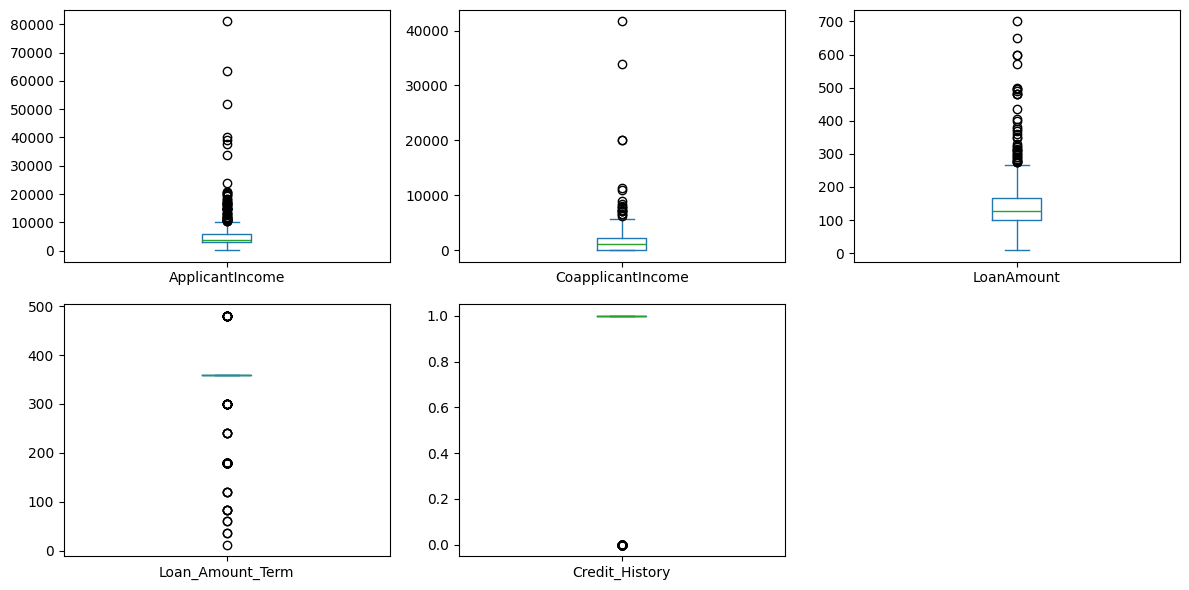

In [37]:
df[['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
    'Loan_Amount_Term', 'Credit_History']].plot(
    kind='box', subplots=True, layout=(2, 3), figsize=(12, 6)
)

plt.tight_layout()
plt.show()

In [38]:
for column in numeric_column:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[column] = df[column].clip(
        lower=lower_bound,
        upper=upper_bound
    )

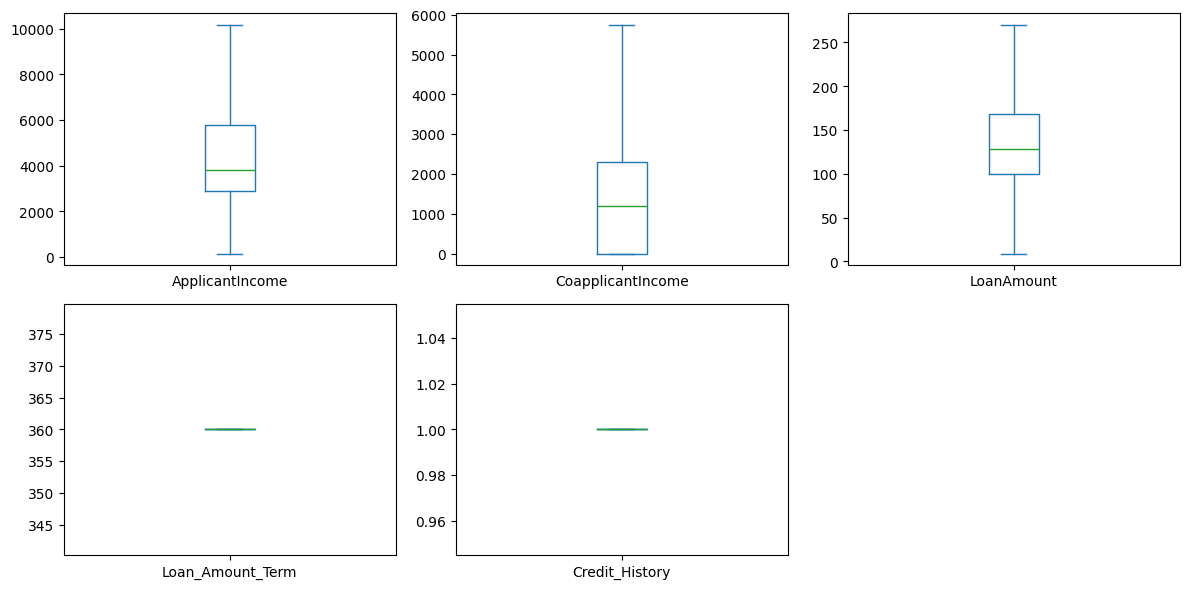

In [39]:
df[['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
    'Loan_Amount_Term', 'Credit_History']].plot(
    kind='box', subplots=True, layout=(2, 3), figsize=(12, 6)
)

plt.tight_layout()
plt.show()

In [40]:
# from sklearn.impute import SimpleImputer

# imputer = SimpleImputer(strategy='median')

# X_train_scaled = imputer.fit_transform(X_train_scaled)
# X_test_scaled = imputer.transform(X_test_scaled)

In [41]:
numeric_column=df.select_dtypes(include='number').columns
numeric_column
for col in numeric_column:
    df[col] = df[col].fillna(df[col].median())

In [61]:
cat_column=df.select_dtypes(include='object').columns
cat_column
for col in cat_column:
    df[col] = df[col].fillna(df[col].mode()[0])

In [62]:
df.isnull().sum()

,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0
Credit_History,0


In [43]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

for col in cat_column:
    df[col] = le.fit_transform(df[col])

In [44]:
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,1,0,0,0,0,5849.0,0.0,128.0,360.0,1.0,2,1
1,1,1,1,0,0,4583.0,1508.0,128.0,360.0,1.0,0,0
2,1,1,0,0,1,3000.0,0.0,66.0,360.0,1.0,2,1
3,1,1,0,1,0,2583.0,2358.0,120.0,360.0,1.0,2,1
4,1,0,0,0,0,6000.0,0.0,141.0,360.0,1.0,2,1


In [45]:
from sklearn.model_selection import train_test_split

X = df.drop('Loan_Status', axis=1)
y = df['Loan_Status']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [46]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (491, 11)
X_test: (123, 11)
y_train: (491,)
y_test: (123,)


In [47]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [48]:
X_train_scaled = scaler.fit_transform(X_train) #it gets the data with mean 0 and varience 1 as i am using std scaler
X_test_scaled = scaler.transform(X_test)#we are avoiding data leakage so no fit here

clearing the null values

In [49]:
print(np.isnan(X_train_scaled).sum())
print(np.isinf(X_train_scaled).sum())

0
0


In [50]:
print(np.isnan(X_train_scaled).sum())
print(np.isinf(X_train_scaled).sum())


0
0


In [51]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=2000, random_state=42)

log_model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=2000, random_state=42)

In [52]:
log_pred = log_model.predict( X_test_scaled) #

In [53]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
print(accuracy_score(y_test, log_pred))
print(classification_report(y_test, log_pred))
print(confusion_matrix(y_test, log_pred))

0.6910569105691057
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        38
           1       0.69      1.00      0.82        85

    accuracy                           0.69       123
   macro avg       0.35      0.50      0.41       123
weighted avg       0.48      0.69      0.56       123

[[ 0 38]
 [ 0 85]]


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Precision: When the model predicts approval, it's correct 69% of the time.



Recall: It identifies 100% of approved loans but 0% of rejected loans.

In [54]:
from sklearn.tree import DecisionTreeClassifier
dt=DecisionTreeClassifier(max_depth=10)
dt.fit(X_train_scaled,y_train)

DecisionTreeClassifier(max_depth=10)

In [55]:
dt_pred=dt.predict(X_test_scaled)

In [56]:
print(accuracy_score(y_test, dt_pred))
print(classification_report(y_test, dt_pred))
print(confusion_matrix(y_test, dt_pred))

0.6585365853658537
              precision    recall  f1-score   support

           0       0.42      0.26      0.32        38
           1       0.72      0.84      0.77        85

    accuracy                           0.66       123
   macro avg       0.57      0.55      0.55       123
weighted avg       0.62      0.66      0.63       123

[[10 28]
 [14 71]]


In [57]:
from sklearn.ensemble import RandomForestClassifier
rf=RandomForestClassifier(n_estimators=100)
rf.fit(X_train_scaled,y_train)

RandomForestClassifier()

In [58]:
rf_pred=rf.predict(X_test_scaled)

In [59]:
print(accuracy_score(y_test, rf_pred))
print(classification_report(y_test, rf_pred))
print(confusion_matrix(y_test, rf_pred))

0.6747967479674797
              precision    recall  f1-score   support

           0       0.45      0.24      0.31        38
           1       0.72      0.87      0.79        85

    accuracy                           0.67       123
   macro avg       0.58      0.55      0.55       123
weighted avg       0.64      0.67      0.64       123

[[ 9 29]
 [11 74]]
